In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (5398, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020.0,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021.0,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021.0,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021.0,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021.0,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:

# Step 4: Explore and clean the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values in selected columns
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Not Rated")
df["date_added"] = df["date_added"].fillna("Not Available")
df["duration"] = df["duration"].fillna("Unknown")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5398 entries, 0 to 5397
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       5398 non-null   object 
 1   type          5398 non-null   object 
 2   title         5397 non-null   object 
 3   director      3515 non-null   object 
 4   cast          4903 non-null   object 
 5   country       4735 non-null   object 
 6   date_added    5397 non-null   object 
 7   release_year  5397 non-null   float64
 8   rating        5397 non-null   object 
 9   duration      5397 non-null   object 
 10  listed_in     5397 non-null   object 
 11  description   5397 non-null   object 
dtypes: float64(1), object(11)
memory usage: 506.2+ KB

Missing Values Before Cleaning:
show_id            0
type               0
title              1
director        1883
cast             495
country          663
date_added         1
release_year       1
rating        

type
Movie      3464
TV Show    1933
TV Sh         1
Name: count, dtype: int64


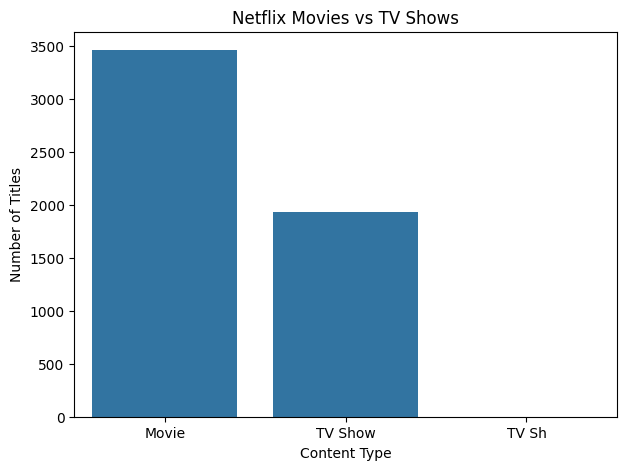

In [3]:

# Count Movies and TV Shows

type_counts = df["type"].value_counts()

print(type_counts)

plt.figure(figsize=(7, 5))
sns.barplot(x=type_counts.index, y=type_counts.values)

plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()


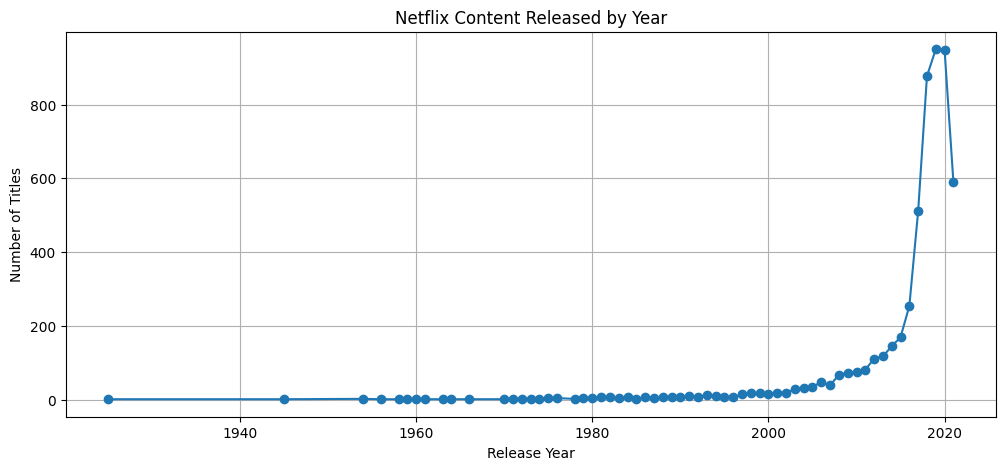

In [4]:

# Netflix content released by year

year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values, marker="o")

plt.title("Netflix Content Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()


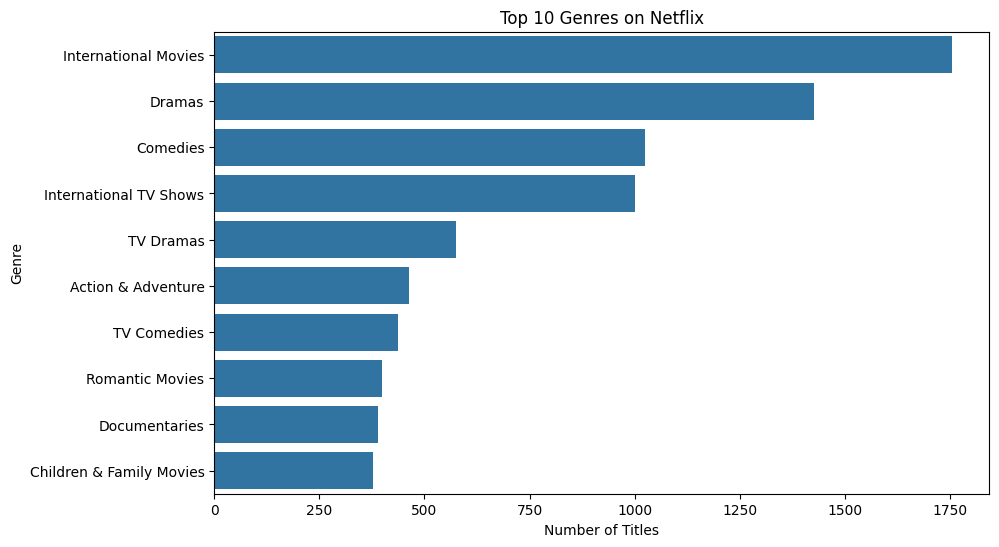

In [5]:

# Analyze the most common genres

genres = df["listed_in"].dropna().str.split(", ").explode()
top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()


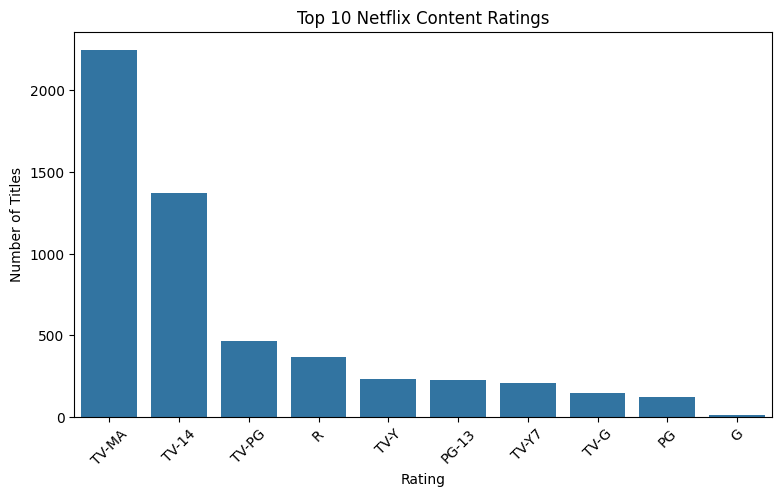

In [6]:

# Analyze content ratings

ratings = df["rating"].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=ratings.index, y=ratings.values)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()


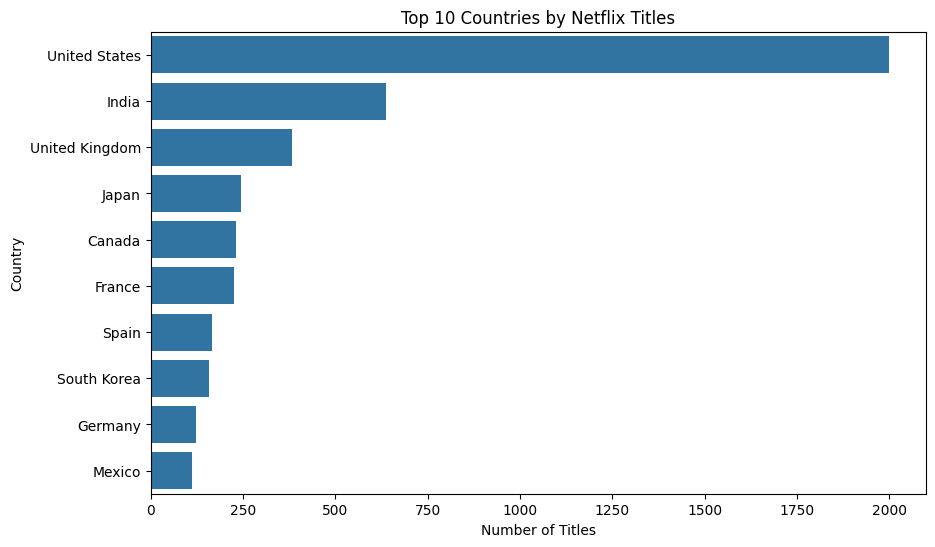

In [7]:

# Top 10 countries by number of titles

countries = df["country"].dropna().str.split(", ").explode()
countries = countries[countries != "Unknown"]
top_countries = countries.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()


## Conclusion

Successfully performed Exploratory Data Analysis (EDA) on the Netflix Movies and TV Shows dataset using Python.

The dataset was cleaned by handling missing values and removing duplicate records. Visualizations were created using Matplotlib and Seaborn to compare Movies and TV Shows, examine release-year trends, identify popular genres, explore content ratings, and analyze country-wise content distribution.

This project helped develop practical skills in data cleaning, analysis, visualization, and communicating insights from real-world data.